In [1]:
pip install gymnasium numpy


In [2]:
import gymnasium as gym
import numpy as np
import random

# 1. Initialise Taxi environment
env = gym.make("Taxi-v4")

# 2. Create Q-table
q_table = np.zeros((
    env.observation_space.n,
    env.action_space.n
))

# 3. Hyperparameters
alpha = 0.7       # Learning rate
gamma = 0.2       # Discount factor
epsilon = 0.4     # Exploration rate

# 4. Initialise variables
all_epochs = []
all_penalties = []
training_memory = []

# 5. Training process (50,000 episodes)
for i in range(1, 50001):

    state, info = env.reset()

    epochs = 0
    penalties = 0
    done = False

    # 6. Train the agent
    while not done:

        # Exploration or exploitation
        if random.uniform(0, 1) < epsilon:

            # Explore: choose random action
            action = env.action_space.sample()

        else:

            # Exploit: choose best-known action
            action = np.argmax(q_table[state])

        # Perform action
        next_state, reward, terminated, truncated, info = env.step(action)

        done = terminated or truncated

        # Get old Q-value
        old_value = q_table[state, action]

        # Get maximum future Q-value
        next_max = np.max(q_table[next_state])

        # Update Q-value
        new_value = (1 - alpha) * old_value + alpha * (
            reward + gamma * next_max * (1 - int(done))
        )

        q_table[state, action] = new_value

        # Count penalties
        if reward == -10:
            penalties += 1

        # Move to next state
        state = next_state

        epochs += 1

    # Save performance metrics
    all_epochs.append(epochs)
    all_penalties.append(penalties)

    # Save Q-table every 100 episodes
    if i % 100 == 0:

        training_memory.append(q_table.copy())

        print("Episode:", i)
        print("Saved Q-table during training:", i)

# 7. Training completed
print("\nTraining finished!")

print("\nFinal Q-table:")
print(q_table)

# 8. Display performance
print("\nAverage timesteps:",
      np.mean(all_epochs))

print("Average penalties:",
      np.mean(all_penalties))

# Close environment
env.close()

Episode: 100
Saved Q-table during training: 100
Episode: 200
Saved Q-table during training: 200
Episode: 300
Saved Q-table during training: 300
Episode: 400
Saved Q-table during training: 400
Episode: 500
Saved Q-table during training: 500
Episode: 600
Saved Q-table during training: 600
Episode: 700
Saved Q-table during training: 700
Episode: 800
Saved Q-table during training: 800
Episode: 900
Saved Q-table during training: 900
Episode: 1000
Saved Q-table during training: 1000
Episode: 1100
Saved Q-table during training: 1100
Episode: 1200
Saved Q-table during training: 1200
Episode: 1300
Saved Q-table during training: 1300
Episode: 1400
Saved Q-table during training: 1400
Episode: 1500
Saved Q-table during training: 1500
Episode: 1600
Saved Q-table during training: 1600
Episode: 1700
Saved Q-table during training: 1700
Episode: 1800
Saved Q-table during training: 1800
Episode: 1900
Saved Q-table during training: 1900
Episode: 2000
Saved Q-table during training: 2000
Episode: 2100
Save

In [3]:
# blue: passenger
# magenta: destination
# yellow: empty taxi
# green: full taxi
# other letters: locations

In [4]:
# At state 499 i will definitely move west
state = 499
print(training_memory[0][state])
print(training_memory[20][state])
print(training_memory[50][state])
print(training_memory[200][state])

[-1.1004 -0.91   -1.008  -0.91   -7.     -9.198 ]
[-0.40184083 -1.07983524 -0.41970463  3.         -9.3982504  -9.39995582]
[-0.4  -1.08 -0.4   3.   -9.4  -9.4 ]
[-0.4  -1.08 -0.4   3.   -9.4  -9.4 ]


In [5]:
# At state 77 i will definitely move east
state = 77
print(training_memory[0][state])
print(training_memory[20][state])
print(training_memory[50][state])
print(training_memory[200][state])

[-0.91       -0.47737455  2.99983596 -0.99248994 -9.33563515 -9.26779219]
[-1.08 -0.4   3.   -1.08 -9.4  -9.4 ]
[-1.08 -0.4   3.   -1.08 -9.4  -9.4 ]
[-1.08 -0.4   3.   -1.08 -9.4  -9.4 ]


In [6]:
# To show that at state 393, how the move evolved
from IPython.display import Markdown, display
def printmd(string):
    display(Markdown(string))

In [7]:
action_dict = {0: "move south"
,1: "move north"
,2: "move east"
,3: "move west"
,4: "pickup passenger"
,5: "dropoff passenger"
}
# Re-initialize the environment with the correct render_mode
env = gym.make("Taxi-v4", render_mode="ansi")
ENV_STATE, info = env.reset()
print(env.render())
state_memory = [i[ENV_STATE] for i in training_memory]
printmd("For state **{}**".format(ENV_STATE))
for step, i in enumerate(state_memory):
  if step % 200==0:
    choice = np.argmax(i)
    printmd("for episode in{}, q table action is{} andit will ... **{}**".format(step*100, choice, action_dict[choice]))
print(i)
print()

+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+




For state **243**

for episode in0, q table action is3 andit will ... **move west**

for episode in20000, q table action is3 andit will ... **move west**

for episode in40000, q table action is3 andit will ... **move west**

[ -1.25        -1.25        -1.25        -1.24999991 -10.24999998
 -10.24999998]



In [8]:
import time
import gymnasium as gym
import numpy as np
from IPython.display import clear_output

def print_frames(frames):
    for i, frame in enumerate(frames):
        clear_output(wait=True)
        print(frame['frame'])
        print(f"Episode: {frame['episode']}")
        print(f"Timestep: {i + 1}")
        print(f"State: {frame['state']}")
        print(f"Action: {frame['action']}")
        print(f"Reward: {frame['reward']}")
        time.sleep(0.8)

# Initialize environment with render mode set to 'ansi'
env = gym.make("Taxi-v4", render_mode="ansi")

total_epochs, total_penalties = 0, 0
episodes = 10
frames = []

for ep in range(episodes):
    state, info = env.reset()
    epochs, penalties, reward = 0, 0, 0
    done = False

    while not done:
        # Exploit: pick best action
        action = np.argmax(q_table[state])

        # gymnasium returns 5 values
        next_state, reward, terminated, truncated, info = env.step(action)
        done = terminated or truncated

        if reward == -10:
            penalties += 1

        # Append the frames
        frames.append({
            'frame': env.render(),
            'episode': ep,
            'state': state,
            'action': action,
            'reward': reward
        })

        state = next_state
        epochs += 1

    total_penalties += penalties
    total_epochs += epochs

print_frames(frames)

print(f"Results after {episodes} episodes:")
print(f"Average timesteps per episode: {total_epochs / episodes}")
print(f"Average penalties per episode: {total_penalties / episodes}")

+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+
  (Dropoff)

Episode: 9
Timestep: 115
State: 479
Action: 5
Reward: 20
Results after 10 episodes:
Average timesteps per episode: 11.5
Average penalties per episode: 0.0


In [9]:

# BASELINE MODEL EVALUATION

import numpy as np
import gymnasium as gym

# Create testing environment
test_env = gym.make("Taxi-v4")

# Evaluation settings
episodes = 100

total_rewards = []
total_timesteps = []
total_penalties = []
successful_deliveries = []

# Test trained Q-table
for episode in range(episodes):

    state, info = test_env.reset()

    done = False
    rewards = 0
    timesteps = 0
    penalties = 0

    while not done:

        # Select best action using trained Q-table
        action = np.argmax(q_table[state])

        # Perform action
        next_state, reward, terminated, truncated, info = (
            test_env.step(action)
        )

        done = terminated or truncated

        # Track performance
        rewards += reward
        timesteps += 1

        if reward == -10:
            penalties += 1

        state = next_state

    total_rewards.append(rewards)
    total_timesteps.append(timesteps)
    total_penalties.append(penalties)

    # Taxi-v4 terminates when the passenger
    # is successfully delivered
    successful_deliveries.append(int(terminated))

# Calculate performance
print("BASELINE MODEL RESULTS")
print("----------------------")

print("Testing episodes:", episodes)

print("Average reward:",
      np.mean(total_rewards))

print("Average timesteps:",
      np.mean(total_timesteps))

print("Average penalties:",
      np.mean(total_penalties))

print("Successful deliveries:",
      sum(successful_deliveries))

print("Success rate:",
      np.mean(successful_deliveries) * 100, "%")

test_env.close()


BASELINE MODEL RESULTS
----------------------
Testing episodes: 100
Average reward: 8.14
Average timesteps: 12.86
Average penalties: 0.0
Successful deliveries: 100
Success rate: 100.0 %


In [10]:

# Preserve the original baseline model
q_table_baseline = q_table.copy()

print("Baseline Q-table saved successfully!")
print("Q-table shape:", q_table_baseline.shape)


Baseline Q-table saved successfully!
Q-table shape: (500, 6)


In [11]:

import gymnasium as gym
import numpy as np
import random

# Create Taxi environment (updated to v4 to fix deprecation error)
env = gym.make("Taxi-v4")

# Initialise a NEW Q-table
q_table_improved = np.zeros(
    (env.observation_space.n, env.action_space.n)
)

# Hyperparameters
alpha = 0.7
gamma = 0.2

epsilon = 1.0
epsilon_decay = 0.9995
min_epsilon = 0.01

episodes = 50000

# Store training performance
training_rewards = []
training_steps = []
training_penalties = []
epsilon_values = []

# Training loop
for episode in range(1, episodes + 1):

    state, info = env.reset()

    done = False
    total_reward = 0
    steps = 0
    penalties = 0

    while not done:

        # Exploration or exploitation
        if random.uniform(0, 1) < epsilon:
            action = env.action_space.sample()
        else:
            action = np.argmax(q_table_improved[state])

        # Perform action
        next_state, reward, terminated, truncated, info = env.step(action)

        done = terminated or truncated

        # Update Q-value
        old_value = q_table_improved[state, action]
        next_max = np.max(q_table_improved[next_state])

        new_value = (1 - alpha) * old_value + alpha * (
            reward + gamma * next_max * (1 - int(done))
        )

        q_table_improved[state, action] = new_value

        # Track performance
        total_reward += reward
        steps += 1

        if reward == -10:
            penalties += 1

        state = next_state

    # Store episode results
    training_rewards.append(total_reward)
    training_steps.append(steps)
    training_penalties.append(penalties)

    # Reduce epsilon after each episode
    epsilon = max(min_epsilon, epsilon * epsilon_decay)
    epsilon_values.append(epsilon)

    # Display progress
    if episode % 5000 == 0:
        print(
            f"Episode: {episode}, "
            f"Epsilon: {epsilon:.4f}, "
            f"Average reward (last 5000): "
            f"{np.mean(training_rewards[-5000:]):.2f}"
        )

env.close()

print("\nImproved agent training completed!")
print("Final epsilon:", epsilon)


Episode: 5000, Epsilon: 0.0820, Average reward (last 5000): -101.76
Episode: 10000, Epsilon: 0.0100, Average reward (last 5000): 6.31
Episode: 15000, Epsilon: 0.0100, Average reward (last 5000): 7.44
Episode: 20000, Epsilon: 0.0100, Average reward (last 5000): 7.46
Episode: 25000, Epsilon: 0.0100, Average reward (last 5000): 7.34
Episode: 30000, Epsilon: 0.0100, Average reward (last 5000): 7.38
Episode: 35000, Epsilon: 0.0100, Average reward (last 5000): 7.42
Episode: 40000, Epsilon: 0.0100, Average reward (last 5000): 7.41
Episode: 45000, Epsilon: 0.0100, Average reward (last 5000): 7.45
Episode: 50000, Epsilon: 0.0100, Average reward (last 5000): 7.43

Improved agent training completed!
Final epsilon: 0.01


In [12]:

def evaluate_agent(q_table_to_test, episodes=100):

    # Use Taxi-v4 to avoid DeprecatedEnv error
    test_env = gym.make("Taxi-v4")

    rewards = []
    timesteps = []
    penalties = []
    successes = []

    for episode in range(episodes):

        state, info = test_env.reset(seed=episode)

        done = False
        total_reward = 0
        steps = 0
        episode_penalties = 0
        successful = False

        while not done:

            action = np.argmax(q_table_to_test[state])

            next_state, reward, terminated, truncated, info = (
                test_env.step(action)
            )

            done = terminated or truncated

            total_reward += reward
            steps += 1

            if reward == -10:
                episode_penalties += 1

            if terminated:
                successful = True

            state = next_state

        rewards.append(total_reward)
        timesteps.append(steps)
        penalties.append(episode_penalties)
        successes.append(int(successful))

    test_env.close()

    return {
        "Average reward": np.mean(rewards),
        "Average timesteps": np.mean(timesteps),
        "Average penalties": np.mean(penalties),
        "Successful deliveries": sum(successes),
        "Success rate (%)": np.mean(successes) * 100
    }


# Evaluate both models
baseline_results = evaluate_agent(q_table_baseline)
improved_results = evaluate_agent(q_table_improved)

print("BASELINE MODEL")
for metric, value in baseline_results.items():
    print(f"{metric}: {value:.2f}")

print("\nIMPROVED MODEL")
for metric, value in improved_results.items():
    print(f"{metric}: {value:.2f}")


BASELINE MODEL
Average reward: 7.69
Average timesteps: 13.31
Average penalties: 0.00
Successful deliveries: 100.00
Success rate (%): 100.00

IMPROVED MODEL
Average reward: 7.69
Average timesteps: 13.31
Average penalties: 0.00
Successful deliveries: 100.00
Success rate (%): 100.00


In [13]:

import matplotlib.pyplot as plt
import numpy as np

print("Matplotlib imported successfully!")


Matplotlib imported successfully!


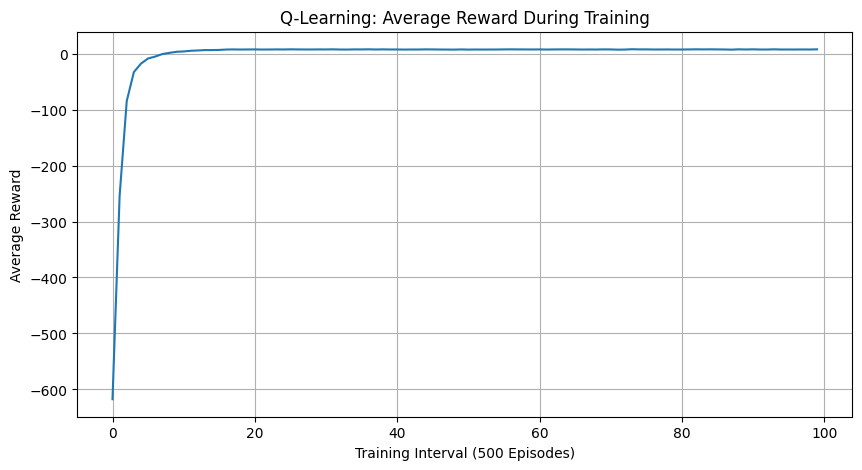

In [14]:

window = 500

average_rewards = [
    np.mean(training_rewards[i:i + window])
    for i in range(0, len(training_rewards), window)
]

plt.figure(figsize=(10, 5))

plt.plot(average_rewards)

plt.title("Q-Learning: Average Reward During Training")
plt.xlabel("Training Interval (500 Episodes)")
plt.ylabel("Average Reward")
plt.grid(True)

plt.show()


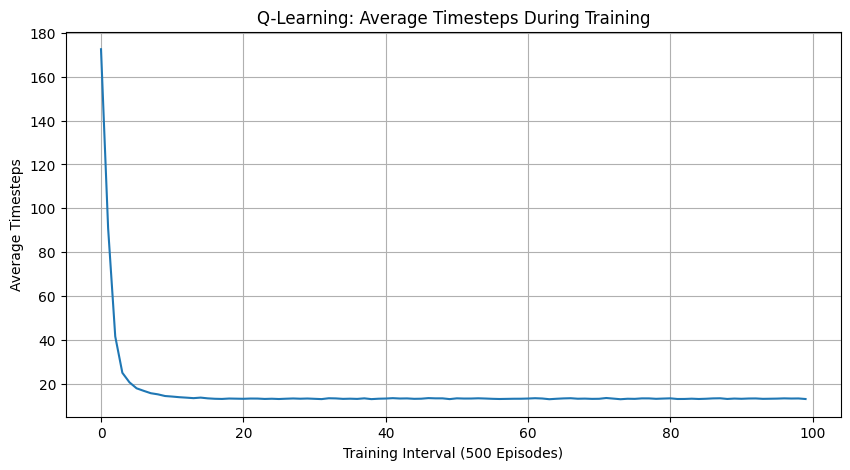

In [15]:

average_steps = [
    np.mean(training_steps[i:i + window])
    for i in range(0, len(training_steps), window)
]

plt.figure(figsize=(10, 5))

plt.plot(average_steps)

plt.title("Q-Learning: Average Timesteps During Training")
plt.xlabel("Training Interval (500 Episodes)")
plt.ylabel("Average Timesteps")
plt.grid(True)

plt.show()


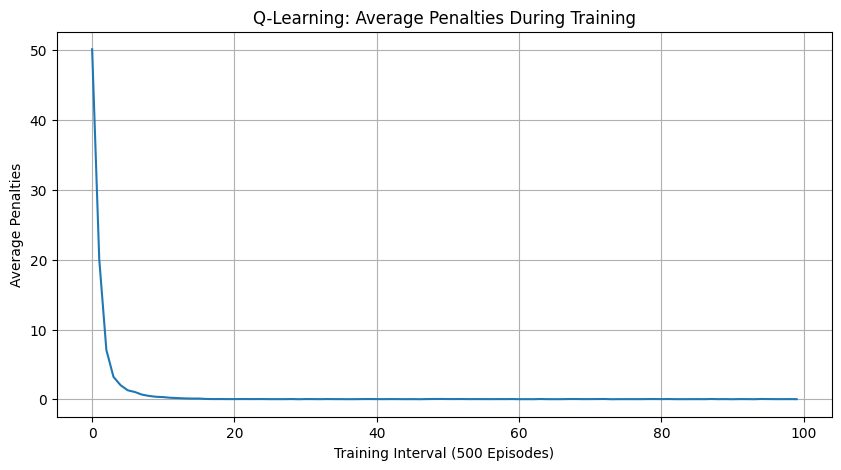

In [16]:

average_penalties = [
    np.mean(training_penalties[i:i + window])
    for i in range(0, len(training_penalties), window)
]

plt.figure(figsize=(10, 5))

plt.plot(average_penalties)

plt.title("Q-Learning: Average Penalties During Training")
plt.xlabel("Training Interval (500 Episodes)")
plt.ylabel("Average Penalties")
plt.grid(True)

plt.show()


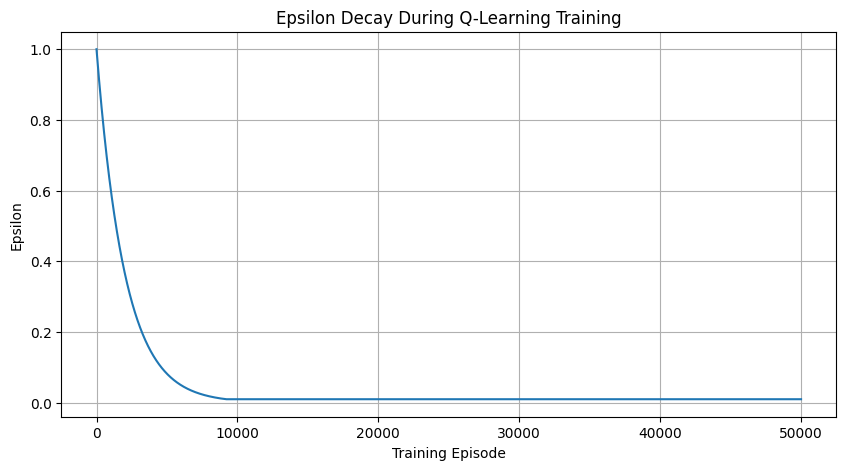

In [17]:

plt.figure(figsize=(10, 5))

plt.plot(epsilon_values)

plt.title("Epsilon Decay During Q-Learning Training")
plt.xlabel("Training Episode")
plt.ylabel("Epsilon")

plt.grid(True)
plt.show()


In [18]:

def train_q_learning(
    alpha,
    gamma,
    epsilon_decay,
    episodes=20000
):

    env = gym.make("Taxi-v3")

    q_table = np.zeros(
        (env.observation_space.n, env.action_space.n)
    )

    epsilon = 1.0
    min_epsilon = 0.01

    for episode in range(episodes):

        state, info = env.reset()
        done = False

        while not done:

            if random.uniform(0, 1) < epsilon:
                action = env.action_space.sample()
            else:
                action = np.argmax(q_table[state])

            next_state, reward, terminated, truncated, info = (
                env.step(action)
            )

            done = terminated or truncated

            old_value = q_table[state, action]
            next_max = np.max(q_table[next_state])

            new_value = (1 - alpha) * old_value + alpha * (
                reward + gamma * next_max * (1 - int(done))
            )

            q_table[state, action] = new_value

            state = next_state

        epsilon = max(
            min_epsilon,
            epsilon * epsilon_decay
        )

    env.close()

    return q_table


In [19]:

import gymnasium as gym
import numpy as np
import random

# Redefining the helper function to use Taxi-v4 to avoid the DeprecatedEnv error
def train_q_learning(
    alpha,
    gamma,
    epsilon_decay,
    episodes=20000
):
    env = gym.make("Taxi-v4")

    q_table = np.zeros(
        (env.observation_space.n, env.action_space.n)
    )

    epsilon = 1.0
    min_epsilon = 0.01

    for episode in range(episodes):

        state, info = env.reset()
        done = False

        while not done:

            if random.uniform(0, 1) < epsilon:
                action = env.action_space.sample()
            else:
                action = np.argmax(q_table[state])

            next_state, reward, terminated, truncated, info = (
                env.step(action)
            )

            done = terminated or truncated

            old_value = q_table[state, action]
            next_max = np.max(q_table[next_state])

            new_value = (1 - alpha) * old_value + alpha * (
                reward + gamma * next_max * (1 - int(done))
            )

            q_table[state, action] = new_value

            state = next_state

        epsilon = max(
            min_epsilon,
            epsilon * epsilon_decay
        )

    env.close()

    return q_table

learning_rates = [0.1, 0.5, 0.7]

learning_rate_results = {}

for lr in learning_rates:

    print("Training with alpha =", lr)

    experiment_q_table = train_q_learning(
        alpha=lr,
        gamma=0.2,
        epsilon_decay=0.9995,
        episodes=20000
    )

    result = evaluate_agent(
        experiment_q_table,
        episodes=100
    )

    learning_rate_results[lr] = result

    print(result)
    print("--------------------------")


Training with alpha = 0.1
{'Average reward': np.float64(-53.95), 'Average timesteps': np.float64(68.65), 'Average penalties': np.float64(0.0), 'Successful deliveries': 70, 'Success rate (%)': np.float64(70.0)}
--------------------------
Training with alpha = 0.5
{'Average reward': np.float64(7.69), 'Average timesteps': np.float64(13.31), 'Average penalties': np.float64(0.0), 'Successful deliveries': 100, 'Success rate (%)': np.float64(100.0)}
--------------------------
Training with alpha = 0.7
{'Average reward': np.float64(7.69), 'Average timesteps': np.float64(13.31), 'Average penalties': np.float64(0.0), 'Successful deliveries': 100, 'Success rate (%)': np.float64(100.0)}
--------------------------


In [20]:

discount_factors = [0.2, 0.6, 0.9]

gamma_results = {}

for g in discount_factors:

    print("Training with gamma =", g)

    experiment_q_table = train_q_learning(
        alpha=0.5,
        gamma=g,
        epsilon_decay=0.9995,
        episodes=20000
    )

    result = evaluate_agent(
        experiment_q_table,
        episodes=100
    )

    gamma_results[g] = result

    print(result)
    print("--------------------------")



Training with gamma = 0.2
{'Average reward': np.float64(7.69), 'Average timesteps': np.float64(13.31), 'Average penalties': np.float64(0.0), 'Successful deliveries': 100, 'Success rate (%)': np.float64(100.0)}
--------------------------
Training with gamma = 0.6
{'Average reward': np.float64(7.69), 'Average timesteps': np.float64(13.31), 'Average penalties': np.float64(0.0), 'Successful deliveries': 100, 'Success rate (%)': np.float64(100.0)}
--------------------------
Training with gamma = 0.9
{'Average reward': np.float64(7.69), 'Average timesteps': np.float64(13.31), 'Average penalties': np.float64(0.0), 'Successful deliveries': 100, 'Success rate (%)': np.float64(100.0)}
--------------------------


In [21]:

import pandas as pd

gamma_comparison = pd.DataFrame(gamma_results).T

gamma_comparison.index.name = "Gamma"

display(gamma_comparison)


,Average reward,Average timesteps,Average penalties,Successful deliveries,Success rate (%)
Gamma,,,,,
0.2,7.69,13.31,0.0,100.0,100.0
0.6,7.69,13.31,0.0,100.0,100.0
0.9,7.69,13.31,0.0,100.0,100.0


In [22]:

epsilon_decay_values = [0.999, 0.9995, 0.9999]

epsilon_results = {}

for decay in epsilon_decay_values:

    print("Training with epsilon decay =", decay)

    experiment_q_table = train_q_learning(
        alpha=0.5,
        gamma=0.6,
        epsilon_decay=decay,
        episodes=20000
    )

    result = evaluate_agent(
        experiment_q_table,
        episodes=100
    )

    epsilon_results[decay] = result

    print(result)
    print("--------------------------")


Training with epsilon decay = 0.999
{'Average reward': np.float64(7.69), 'Average timesteps': np.float64(13.31), 'Average penalties': np.float64(0.0), 'Successful deliveries': 100, 'Success rate (%)': np.float64(100.0)}
--------------------------
Training with epsilon decay = 0.9995
{'Average reward': np.float64(7.69), 'Average timesteps': np.float64(13.31), 'Average penalties': np.float64(0.0), 'Successful deliveries': 100, 'Success rate (%)': np.float64(100.0)}
--------------------------
Training with epsilon decay = 0.9999
{'Average reward': np.float64(7.69), 'Average timesteps': np.float64(13.31), 'Average penalties': np.float64(0.0), 'Successful deliveries': 100, 'Success rate (%)': np.float64(100.0)}
--------------------------


In [23]:

import pandas as pd

epsilon_comparison = pd.DataFrame(
    epsilon_results
).T

epsilon_comparison.index.name = "Epsilon Decay"

display(epsilon_comparison)


,Average reward,Average timesteps,Average penalties,Successful deliveries,Success rate (%)
Epsilon Decay,,,,,
0.9990,7.69,13.31,0.0,100.0,100.0
0.9995,7.69,13.31,0.0,100.0,100.0
0.9999,7.69,13.31,0.0,100.0,100.0


In [24]:

final_q_table = train_q_learning(
    alpha=0.5,
    gamma=0.6,
    epsilon_decay=0.9995,
    episodes=20000
)

print("Final Q-learning model trained!")
print("Q-table shape:", final_q_table.shape)


Final Q-learning model trained!
Q-table shape: (500, 6)


In [25]:

import numpy as np

np.save("taxi_q_table.npy", final_q_table)

print("Q-table saved successfully!")


Q-table saved successfully!


In [26]:

loaded_q_table = np.load("taxi_q_table.npy")

print("Model loaded successfully!")
print("Loaded Q-table shape:", loaded_q_table.shape)

print(
    "Are both Q-tables identical?",
    np.array_equal(final_q_table, loaded_q_table)
)


Model loaded successfully!
Loaded Q-table shape: (500, 6)
Are both Q-tables identical? True


In [27]:
test_env = gym.make("Taxi-v4")

state, info = test_env.reset(seed=42)
done = False
total_reward = 0

while not done:

    action = np.argmax(loaded_q_table[state])

    state, reward, terminated, truncated, info = (
        test_env.step(action)
    )

    done = terminated or truncated
    total_reward += reward

print("Test episode reward:", total_reward)
print("Successful delivery:", terminated)

test_env.close()

Test episode reward: 8
Successful delivery: True


In [28]:

!pip install -q gymnasium matplotlib numpy


In [29]:

import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

from matplotlib.patches import Rectangle, Circle, Polygon
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display


In [30]:

# Use the existing trained Q-table.
# No retraining takes place.

if "loaded_q_table" in globals():
    visual_q_table = loaded_q_table.copy()

elif "final_q_table" in globals():
    visual_q_table = final_q_table.copy()

elif "q_table" in globals():
    visual_q_table = q_table.copy()

else:
    raise ValueError(
        "No trained Q-table found. Run your previous training "
        "or model-loading cell first."
    )

print("Existing Q-table connected!")
print("Shape:", visual_q_table.shape)
print("Number of states:", visual_q_table.shape[0])
print("Number of actions:", visual_q_table.shape[1])


Existing Q-table connected!
Shape: (500, 6)
Number of states: 500
Number of actions: 6


In [31]:
env = gym.make("Taxi-v4")

# Start a reproducible test episode
state, info = env.reset(seed=42)

# Store the journey
journey = []

done = False
total_reward = 0
step_count = 0

while not done:

    # Greedy action from your existing Q-table
    action = int(np.argmax(visual_q_table[state]))

    next_state, reward, terminated, truncated, info = (
        env.step(action)
    )

    done = terminated or truncated

    # Decode Taxi-v4 state
    taxi_row, taxi_col, passenger_location, destination = (
        env.unwrapped.decode(next_state)
    )

    journey.append({
        "state": next_state,
        "taxi_row": int(taxi_row),
        "taxi_col": int(taxi_col),
        "passenger": int(passenger_location),
        "destination": int(destination),
        "action": int(action),
        "reward": int(reward),
        "terminated": bool(terminated),
        "truncated": bool(truncated)
    })

    total_reward += reward
    step_count += 1
    state = next_state

env.close()

print("Journey recorded!")
print("Total steps:", step_count)
print("Total reward:", total_reward)
print("Successful delivery:", journey[-1]["terminated"])

Journey recorded!
Total steps: 13
Total reward: 8
Successful delivery: True


In [32]:

# Taxi-v3 landmark positions: (row, column)
landmarks = {
    0: ("RED", (0, 0)),
    1: ("GREEN", (0, 4)),
    2: ("YELLOW", (4, 0)),
    3: ("BLUE", (4, 3))
}

def grid_y(row):
    # Convert environment row to plot coordinates
    return 4 - row


def draw_house(ax, x, y, label):
    """Draw a small colourful house."""

    colours = {
        "RED": "#F28B82",
        "GREEN": "#81C995",
        "YELLOW": "#FDD663",
        "BLUE": "#8AB4F8"
    }

    colour = colours[label]

    # House body
    body = Rectangle(
        (x + 0.13, y - 0.28),
        0.48, 0.40,
        facecolor=colour,
        edgecolor="#333333",
        linewidth=1.2,
        zorder=3
    )
    ax.add_patch(body)

    # Roof
    roof = Polygon(
        [
            (x + 0.08, y + 0.12),
            (x + 0.37, y + 0.38),
            (x + 0.66, y + 0.12)
        ],
        closed=True,
        facecolor="#9B4D3A",
        edgecolor="#333333",
        linewidth=1.1,
        zorder=4
    )
    ax.add_patch(roof)

    # Door
    door = Rectangle(
        (x + 0.31, y - 0.28),
        0.12, 0.24,
        facecolor="#795548",
        zorder=5
    )
    ax.add_patch(door)

    ax.text(
        x + 0.37, y - 0.43,
        label,
        ha="center",
        fontsize=6,
        weight="bold",
        color="#333333"
    )


def draw_passenger(ax, x, y):
    """Draw a small waiting passenger."""

    # Head
    ax.add_patch(Circle(
        (x - 0.22, y + 0.12),
        0.085,
        facecolor="#F5CBA7",
        edgecolor="#333333",
        zorder=9
    ))

    # Body
    ax.add_patch(Rectangle(
        (x - 0.29, y - 0.12),
        0.14, 0.20,
        facecolor="#8E44AD",
        edgecolor="#333333",
        zorder=8
    ))

    # Legs
    ax.plot(
        [x - 0.25, x - 0.30],
        [y - 0.12, y - 0.23],
        color="#333333",
        linewidth=2,
        zorder=8
    )

    ax.plot(
        [x - 0.19, x - 0.14],
        [y - 0.12, y - 0.23],
        color="#333333",
        linewidth=2,
        zorder=8
    )


def draw_taxi(ax, x, y):
    """Draw a yellow top-down taxi car."""

    # Wheels
    for wx in [x - 0.22, x + 0.22]:
        for wy in [y - 0.19, y + 0.19]:
            ax.add_patch(Circle(
                (wx, wy),
                0.065,
                facecolor="#252525",
                zorder=10
            ))

    # Main car body
    ax.add_patch(Rectangle(
        (x - 0.25, y - 0.29),
        0.50, 0.58,
        facecolor="#FFC928",
        edgecolor="#333333",
        linewidth=1.8,
        zorder=11
    ))

    # Windows
    ax.add_patch(Rectangle(
        (x - 0.17, y - 0.12),
        0.34, 0.24,
        facecolor="#7EC8E3",
        edgecolor="#333333",
        linewidth=1,
        zorder=12
    ))

    # Taxi roof sign
    ax.add_patch(Rectangle(
        (x - 0.10, y + 0.18),
        0.20, 0.10,
        facecolor="#FFFFFF",
        edgecolor="#333333",
        zorder=13
    ))

    ax.text(
        x, y + 0.23,
        "TAXI",
        ha="center",
        va="center",
        fontsize=5,
        weight="bold",
        zorder=14
    )


def draw_destination(ax, x, y):
    """Draw a destination marker."""

    ax.plot(
        [x + 0.28, x + 0.28],
        [y - 0.05, y + 0.40],
        color="#333333",
        linewidth=2,
        zorder=7
    )

    flag = Polygon(
        [
            (x + 0.28, y + 0.40),
            (x + 0.60, y + 0.30),
            (x + 0.28, y + 0.20)
        ],
        closed=True,
        facecolor="#2ECC71",
        edgecolor="#333333",
        zorder=7
    )
    ax.add_patch(flag)


In [33]:

action_names = {
    0: "Move South",
    1: "Move North",
    2: "Move East",
    3: "Move West",
    4: "Pick Up Passenger",
    5: "Drop Off Passenger"
}

fig, ax = plt.subplots(figsize=(9, 8))


def draw_game(frame):

    ax.clear()

    current = journey[frame]

    taxi_row = current["taxi_row"]
    taxi_col = current["taxi_col"]
    passenger_location = current["passenger"]
    destination = current["destination"]

    # Background
    ax.set_facecolor("#E8F1F5")

    # Draw 5 x 5 road grid
    for row in range(5):
        for col in range(5):

            y = grid_y(row)

            ax.add_patch(Rectangle(
                (col - 0.5, y - 0.5),
                1, 1,
                facecolor="#DCE7E9",
                edgecolor="#FFFFFF",
                linewidth=3,
                zorder=1
            ))

            # Road markings
            ax.plot(
                [col - 0.35, col + 0.35],
                [y - 0.35, y - 0.35],
                color="#FFFFFF",
                linewidth=1,
                linestyle="--",
                zorder=2
            )

    # Draw four houses
    for landmark_id, (label, position) in landmarks.items():

        house_row, house_col = position
        house_y = grid_y(house_row)

        draw_house(
            ax,
            house_col,
            house_y,
            label
        )

    # Destination marker
    dest_label, dest_position = landmarks[destination]

    dest_row, dest_col = dest_position

    draw_destination(
        ax,
        dest_col,
        grid_y(dest_row)
    )

    # Draw passenger if not inside taxi
    if passenger_location < 4:

        passenger_label, passenger_position = (
            landmarks[passenger_location]
        )

        passenger_row, passenger_col = passenger_position

        draw_passenger(
            ax,
            passenger_col,
            grid_y(passenger_row)
        )

        passenger_status = "Waiting for pickup"

    else:
        passenger_status = "Inside the taxi"

    # Draw taxi
    taxi_y = grid_y(taxi_row)

    draw_taxi(
        ax,
        taxi_col,
        taxi_y
    )

    # Calculate cumulative reward
    cumulative_reward = sum(
        item["reward"] for item in journey[:frame + 1]
    )

    # Delivery status
    if current["terminated"]:
        delivery_status = "DELIVERY SUCCESSFUL!"
        status_colour = "#168A45"

    elif current["truncated"]:
        delivery_status = "EPISODE TIME LIMIT"
        status_colour = "#C0392B"

    else:
        delivery_status = "Journey in progress"
        status_colour = "#245B9E"

    # Title
    ax.set_title(
        "AUTONOMOUS TAXI – REINFORCEMENT LEARNING",
        fontsize=15,
        fontweight="bold",
        color="#183B56",
        pad=18
    )

    # Information panel
    info_text = (
        f"Episode: 1    |    Step: {frame + 1}/{len(journey)}\n"
        f"Action: {action_names[current['action']]}\n"
        f"Passenger: {passenger_status}\n"
        f"Destination: {dest_label}\n"
        f"Current reward: {current['reward']}    |    "
        f"Total reward: {cumulative_reward}"
    )

    ax.text(
        0.02, -0.12,
        info_text,
        transform=ax.transAxes,
        fontsize=10,
        va="top",
        color="#183B56",
        bbox=dict(
            boxstyle="round,pad=0.6",
            facecolor="white",
            edgecolor="#AAB7B8"
        )
    )

    ax.text(
        0.98, -0.12,
        delivery_status,
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=10,
        fontweight="bold",
        color=status_colour
    )

    # Grid settings
    ax.set_xlim(-0.5, 4.5)
    ax.set_ylim(-0.65, 4.5)
    ax.set_aspect("equal")

    ax.set_xticks(range(5))
    ax.set_yticks(range(5))

    ax.set_xticklabels(["0", "1", "2", "3", "4"])
    ax.set_yticklabels(["4", "3", "2", "1", "0"])

    ax.set_xlabel("Taxi column")
    ax.set_ylabel("Taxi row")

    ax.grid(False)


# Create animation
taxi_animation = FuncAnimation(
    fig,
    draw_game,
    frames=len(journey),
    interval=650,
    repeat=False
)

plt.close(fig)

# Display animation inside Google Colab
display(HTML(taxi_animation.to_jshtml()))


In [34]:

# Save the animation as a GIF
taxi_animation.save(
    "taxi_agent_animation.gif",
    writer="pillow",
    fps=2
)

print("Animation saved successfully!")


Animation saved successfully!


In [35]:


from google.colab import files

files.download("taxi_agent_animation.gif")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>